# FRED-MD: unpenalized joint CV over Huber epsilon and change-point count

This is a deliberately unpenalized control. Each `(epsilon, segment count)`
pair is one candidate in a single CV surface. WERM segmentation and every
hard segment refit use Huber loss with that candidate's epsilon. Absolute
loss is used only to score held-out predictions. There is no L1 or L2
coefficient penalty and no partition penalty.

The stored data retain the bundled McScan preprocessing: FRED transforms,
per-series centering/scaling, global 99.9% absolute truncation, and a design
formed from six PCA factors plus idiosyncratic components.

In [1]:
from pathlib import Path
import itertools
import json
import os
import pickle
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from WERM.experiment_utils import weighted_erm_joint_cv

ROOT = Path.cwd()
DATA_PATH = ROOT / "FRED-MD data" / "fredmd_data.pkl"
RESULT_DIR = ROOT / "results" / "FRED-MD_unpenalized-huber-epsilon-joint-cv"
FIGURE_DIR = ROOT / "figures" / "FRED-MD_unpenalized-huber-epsilon-joint-cv"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_PATH = RESULT_DIR / "summary.json"
N_JOBS = min(36, os.cpu_count() or 1)

with DATA_PATH.open("rb") as handle:
    fred = pickle.load(handle)
X = np.asarray(fred["X"], dtype=float)
y = np.asarray(fred["y"], dtype=float).reshape(-1)
dates = np.asarray(fred["date"]).astype(str).reshape(-1)
n, p = X.shape
assert X.shape == (773, 114) and y.shape == (773,)

def absolute_loss(prediction, truth):
    return jnp.abs(prediction - truth)

def make_huber(epsilon):
    epsilon = float(epsilon)
    def huber(prediction, truth):
        residual = prediction - truth
        absolute = jnp.abs(residual)
        return jnp.where(
            absolute <= epsilon,
            0.5 * jnp.square(residual),
            epsilon * (absolute - 0.5 * epsilon),
        )
    return huber

## Predeclared grid

The response standard deviation is about 0.88. Epsilon therefore spans very
robust behavior (0.25) through near-least-squares behavior for most residuals
(3 and 5). Candidate segment counts 1--5 correspond to 0--4 change points.
The primary odd/even split at n/40 is accompanied by a five-fold check and an
n/30 spacing check; each check independently selects from its full Cartesian
`(epsilon, L)` surface.

In [2]:
EPSILONS = (0.25, 0.5, 0.75, 1.0, 1.35, 2.0, 3.0, 5.0)
SEGMENT_COUNTS = (1, 2, 3, 4, 5)
SENSITIVITIES = (
    {"num_folds": 2, "delta_fraction": 1/40},
    {"num_folds": 5, "delta_fraction": 1/40},
    {"num_folds": 2, "delta_fraction": 1/30},
)
list(itertools.product(EPSILONS, SEGMENT_COUNTS))[:10], len(EPSILONS) * len(SEGMENT_COUNTS)

([(0.25, 1),
  (0.25, 2),
  (0.25, 3),
  (0.25, 4),
  (0.25, 5),
  (0.5, 1),
  (0.5, 2),
  (0.5, 3),
  (0.5, 4),
  (0.5, 5)],
 40)

In [3]:
sensitivity_records = []
for sensitivity in SENSITIVITIES:
    started = time.perf_counter()
    candidate_rows = []
    per_epsilon_cp = {}
    for epsilon in EPSILONS:
        selected, cp, diagnostics = weighted_erm_joint_cv(
            X=X, y=y, M=make_huber(epsilon), M_scorer=absolute_loss,
            Lmax=max(SEGMENT_COUNTS),
            delta_fraction=sensitivity["delta_fraction"],
            l1_constants=(0.0,), num_folds=sensitivity["num_folds"],
            n_jobs=N_JOBS, standardize_y=False,
            selection_strategy="exhaustive", return_diagnostics=True,
            penalty_norm="none", segment_counts=SEGMENT_COUNTS,
        )
        per_epsilon_cp[float(epsilon)] = {
            "selected_segments": int(selected[0]),
            "cp": np.asarray(cp, dtype=int).reshape(-1).tolist(),
        }
        for candidate, score in zip(diagnostics["candidates"], diagnostics["scores"]):
            candidate_rows.append({
                "epsilon": float(epsilon),
                "segments": int(candidate[0]),
                "change_points": int(candidate[0] - 1),
                "cv_total": float(score),
                "cv_mean": float(score / n),
            })

    best = min(candidate_rows, key=lambda row: row["cv_total"])
    selected_cp = per_epsilon_cp[best["epsilon"]]["cp"]
    assert per_epsilon_cp[best["epsilon"]]["selected_segments"] == best["segments"]
    baseline = min(row["cv_total"] for row in candidate_rows if row["change_points"] == 0)
    record = {
        **sensitivity,
        "selected_epsilon": best["epsilon"],
        "selected_segments": best["segments"],
        "selected_change_points": best["change_points"],
        "estimated_change_points": selected_cp,
        "estimated_dates": dates[np.asarray(selected_cp, dtype=int)].tolist(),
        "selected_cv_mean": best["cv_mean"],
        "best_zero_cp_cv_mean": float(baseline / n),
        "relative_improvement_vs_zero_pct": float((baseline - best["cv_total"]) / baseline * 100),
        "candidate_scores": candidate_rows,
        "elapsed_seconds": time.perf_counter() - started,
    }
    sensitivity_records.append(record)
    print(json.dumps({key: record[key] for key in (
        "num_folds", "delta_fraction", "selected_epsilon",
        "selected_change_points", "estimated_dates",
        "relative_improvement_vs_zero_pct", "elapsed_seconds",
    )}, indent=2), flush=True)

\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 5, Lmax: 5
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 4, Lmax: 4


100%|██████████| 1/1 [00:00<00:00, 118.43it/s]

100%|██████████| 1/1 [00:00<00:00,  7.41it/s]

  6%|▌         | 11574/194580 [00:00<00:01, 115731.28it/s]

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

 18%|█▊        | 35519/194580 [00:00<00:01, 118903.68it/s]


 25%|██▍       | 47751/194580 [00:00<00:01, 120248.34it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

 31%|███       | 59921/194580 [00:00<00:01, 120770.80it/s]


 43%|████▎     | 83811/194580 [00:00<00:00, 117739.23it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.



 62%|██████▏   | 120373/194580 [00:01<00:00, 120691.36it/s]

... (1,048 outputs left out)

\Delta: 1, n: 50, Lmin: 1, Lmax: 1


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

{
  "num_folds": 2,
  "delta_fraction": 0.03333333333333333,
  "selected_epsilon": 1.0,
  "selected_change_points": 0,
  "estimated_dates": [],
  "relative_improvement_vs_zero_pct": 0.0,
  "elapsed_seconds": 284.3772753654048
}


In [4]:
summary = {
    "notebook": "FRED-MD Unpenalized Huber Joint CV.ipynb",
    "loss_contract": {
        "segmentation": "Huber(epsilon candidate)",
        "hard_segment_refits": "Huber(same epsilon candidate)",
        "heldout_scoring_only": "absolute_loss",
        "coefficient_penalty": "none",
    },
    "epsilons": list(EPSILONS),
    "segment_counts": list(SEGMENT_COUNTS),
    "records": sensitivity_records,
}
with SUMMARY_PATH.open("w") as handle:
    json.dump(summary, handle, indent=2)

selection_table = pd.DataFrame([{
    "folds": record["num_folds"], "delta": record["delta_fraction"],
    "epsilon": record["selected_epsilon"],
    "selected CPs": record["selected_change_points"],
    "dates": ";".join(record["estimated_dates"]),
    "CV improvement vs zero (%)": record["relative_improvement_vs_zero_pct"],
} for record in sensitivity_records])
selection_table.to_csv(RESULT_DIR / "selections.csv", index=False)
selection_table

,folds,delta,epsilon,selected CPs,dates,CV improvement vs zero (%)
0,2,0.025000,1.00,0,,0.0
1,5,0.025000,0.75,0,,0.0
2,2,0.033333,1.00,0,,0.0


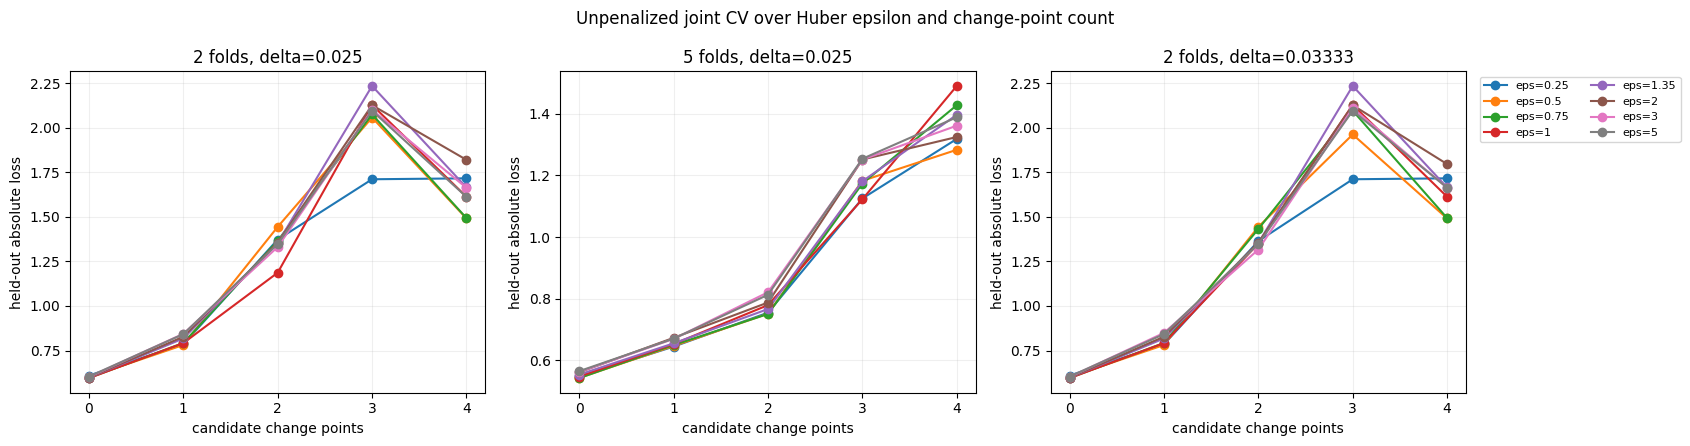

In [5]:
figure, axes = plt.subplots(1, len(sensitivity_records), figsize=(17, 4.5), sharey=False)
for axis, record in zip(axes, sensitivity_records):
    surface = pd.DataFrame(record["candidate_scores"])
    for epsilon, group in surface.groupby("epsilon"):
        axis.plot(group["change_points"], group["cv_mean"], marker="o", label=f"eps={epsilon:g}")
    axis.set_title(f'{record["num_folds"]} folds, delta={record["delta_fraction"]:.4g}')
    axis.set_xlabel("candidate change points")
    axis.set_ylabel("held-out absolute loss")
    axis.set_xticks(range(5))
    axis.grid(alpha=0.2)
axes[-1].legend(fontsize=8, ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
figure.suptitle("Unpenalized joint CV over Huber epsilon and change-point count")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "epsilon_change_count_cv_surfaces.png", dpi=190, bbox_inches="tight")
plt.show()